# MSCS 634 – Project Deliverable 2
## Regression Modeling and Performance Evaluation

**Dataset:** UCI Online Retail  
**Target:** Invoice-level sales revenue (`InvoiceRevenue`, GBP)  
**Models:** Ridge Regression and Random Forest Regression

### Objective
This notebook continues Deliverable 1 by using the cleaned UCI Online Retail transactions to engineer invoice-level predictors, train two regression models, evaluate holdout performance, and use cross-validation to examine generalization.

**Prediction scope:** The model estimates the total value of an invoice from features describing its transaction basket, timing, and country. It is not a forecast made before a customer begins shopping. Quantity and unit-price summaries are available basket attributes and are naturally related to invoice value; this relationship is disclosed to avoid overstating the model's predictive scope.


## 1. Imports and reproducibility

The notebook uses the same UCI Online Retail workbook and cleaning logic as Deliverable 1.

In [1]:
# Uncomment if the required packages are not installed.
# %pip install pandas numpy matplotlib seaborn openpyxl scikit-learn

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error
)
from sklearn.base import clone

RANDOM_STATE = 42
DATA_PATH = "data/Online Retail.xlsx"
FIGURE_DIR = "visualizations"
os.makedirs(FIGURE_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


## 2. Load and clean the transaction data

Consistent with Deliverable 1, exact duplicates and rows with unusable dates or numeric transaction fields are removed. Cancellation invoices and non-positive quantities/prices are excluded from the sales modeling subset. Returns and cancellations remain meaningful operational records, but they are not part of this positive-sales invoice-value prediction task.

In [3]:
raw_df = pd.read_excel(DATA_PATH, engine="openpyxl")
print(f"Original data shape: {raw_df.shape}")

df = raw_df.copy()
df.columns = df.columns.str.strip()

for col in ["InvoiceNo", "StockCode", "Country"]:
    df[col] = df[col].astype("string").str.strip()

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

df = df.drop_duplicates().dropna(
    subset=["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"]
).copy()

# Keep ordinary sales invoices with positive quantities and prices.
sales_df = df[
    (~df["InvoiceNo"].str.upper().str.startswith("C", na=False))
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
].copy()

sales_df["Country"] = sales_df["Country"].fillna("Unknown")
sales_df["LineRevenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

print(f"Clean sales transaction lines: {len(sales_df):,}")
print(f"Unique sales invoices: {sales_df['InvoiceNo'].nunique():,}")
display(sales_df.head())


Original data shape: (541909, 8)
Clean sales transaction lines: 524,878
Unique sales invoices: 19,960


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineRevenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,"17,850.000",United Kingdom,15.300
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom,20.340
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,"17,850.000",United Kingdom,22.000
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom,20.340
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom,20.340


## 3. Feature engineering and target construction

The modeling unit is one invoice. Transaction lines are aggregated to create the target and predictors. Calendar features are derived from the invoice timestamp. The invoice number and customer ID are excluded as identifiers rather than meaningful generalizable predictors. Missing unit-price standard deviations (single-line invoices) are set to zero.

In [4]:
# Create time features at the transaction-line level before aggregation.
sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour
sales_df["DayOfWeek"] = sales_df["InvoiceDate"].dt.dayofweek
sales_df["Month"] = sales_df["InvoiceDate"].dt.month
sales_df["DayOfMonth"] = sales_df["InvoiceDate"].dt.day
sales_df["IsWeekend"] = (sales_df["DayOfWeek"] >= 5).astype(int)

# Aggregate sales lines into one row per invoice.
invoice_df = (
    sales_df.groupby("InvoiceNo")
    .agg(
        InvoiceRevenue=("LineRevenue", "sum"),
        InvoiceDate=("InvoiceDate", "min"),
        Country=("Country", "first"),
        InvoiceLineCount=("StockCode", "size"),
        UniqueProducts=("StockCode", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        MeanUnitPrice=("UnitPrice", "mean"),
        MedianUnitPrice=("UnitPrice", "median"),
        MaxUnitPrice=("UnitPrice", "max"),
        UnitPriceStd=("UnitPrice", "std"),
        Hour=("Hour", "first"),
        DayOfWeek=("DayOfWeek", "first"),
        Month=("Month", "first"),
        DayOfMonth=("DayOfMonth", "first"),
        IsWeekend=("IsWeekend", "first"),
    )
    .reset_index()
)

invoice_df["UnitPriceStd"] = invoice_df["UnitPriceStd"].fillna(0)
invoice_df["QuantityPerLine"] = (
    invoice_df["TotalQuantity"] / invoice_df["InvoiceLineCount"]
)
invoice_df["ProductsPerLine"] = (
    invoice_df["UniqueProducts"] / invoice_df["InvoiceLineCount"]
)
invoice_df["LogInvoiceLineCount"] = np.log1p(invoice_df["InvoiceLineCount"])
invoice_df["LogTotalQuantity"] = np.log1p(invoice_df["TotalQuantity"])
invoice_df["LogMeanUnitPrice"] = np.log1p(invoice_df["MeanUnitPrice"])

print(f"Invoice-level modeling data: {invoice_df.shape[0]:,} rows")
print(f"Target total revenue: £{invoice_df['InvoiceRevenue'].sum():,.2f}")
display(invoice_df.head())
display(invoice_df["InvoiceRevenue"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
).to_frame())


Invoice-level modeling data: 19,960 rows
Target total revenue: £10,642,110.80


,InvoiceNo,InvoiceRevenue,InvoiceDate,Country,InvoiceLineCount,UniqueProducts,TotalQuantity,MeanUnitPrice,MedianUnitPrice,MaxUnitPrice,UnitPriceStd,Hour,DayOfWeek,Month,DayOfMonth,IsWeekend,QuantityPerLine,ProductsPerLine,LogInvoiceLineCount,LogTotalQuantity,LogMeanUnitPrice
0,536365,139.120,2010-12-01 08:26:00,United Kingdom,7,7,40,3.910,3.390,7.650,1.737,8,2,12,1,0,5.714,1.000,2.079,3.714,1.591
1,536366,22.200,2010-12-01 08:28:00,United Kingdom,2,2,12,1.850,1.850,1.850,0.000,8,2,12,1,0,6.000,1.000,1.099,2.565,1.047
2,536367,278.730,2010-12-01 08:34:00,United Kingdom,12,12,83,4.853,4.600,9.950,2.773,8,2,12,1,0,6.917,1.000,2.565,4.431,1.767
3,536368,70.050,2010-12-01 08:34:00,United Kingdom,4,4,15,4.775,4.950,4.950,0.350,8,2,12,1,0,3.750,1.000,1.609,2.773,1.754
4,536369,17.850,2010-12-01 08:35:00,United Kingdom,1,1,3,5.950,5.950,5.950,0.000,8,2,12,1,0,3.000,1.000,0.693,1.386,1.939


,InvoiceRevenue
count,"19,960.000"
mean,533.172
std,"1,780.412"
min,0.380
50%,303.300
90%,938.391
95%,"1,585.921"
99%,"4,821.165"
max,"168,469.600"


### Feature definitions

- **Basket size:** invoice line count, unique products, total quantity.
- **Price profile:** mean, median, maximum, and standard deviation of unit price.
- **Derived basket features:** quantity per line, products per line, and log-transformed size/price variables.
- **Time:** hour, weekday, month, day of month, and weekend indicator.
- **Context:** country, encoded as categorical data.

The target is invoice-level revenue: the sum of `Quantity × UnitPrice` across an invoice's valid sales lines. No target-derived revenue aggregate is used as a predictor. Quantity and unit-price summaries are observed basket attributes and remain naturally related to invoice value; this is an estimate from basket details, not a claim that revenue can be predicted independently of basket contents.


## 4. Define predictors and split the data

A held-out 20% test set is reserved for final evaluation. All preprocessing is fitted inside each model pipeline to prevent information from the test set being used during training.

In [5]:
target = "InvoiceRevenue"

feature_columns = [
    "InvoiceLineCount", "UniqueProducts", "TotalQuantity",
    "MeanUnitPrice", "MedianUnitPrice", "MaxUnitPrice", "UnitPriceStd",
    "Hour", "DayOfWeek", "Month", "DayOfMonth", "IsWeekend",
    "QuantityPerLine", "ProductsPerLine",
    "LogInvoiceLineCount", "LogTotalQuantity", "LogMeanUnitPrice",
    "Country"
]

X = invoice_df[feature_columns].copy()
y = invoice_df[target].copy()

numeric_features = [c for c in feature_columns if c != "Country"]
categorical_features = ["Country"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Training invoices: {len(X_train):,}")
print(f"Test invoices: {len(X_test):,}")


Training invoices: 15,968
Test invoices: 3,992


## 5. Build two regression models

**Ridge Regression** is a regularized linear model. Numeric variables are imputed and standardized; country is one-hot encoded. The regularization strength is set to `alpha=100`.

**Random Forest Regression** captures nonlinear relationships and interactions. It uses the same categorical encoding and median imputation for numeric predictors. Model settings are fixed for reproducibility; this deliverable focuses on comparison rather than extensive hyperparameter tuning.

In [6]:
# Preprocessing used by the linear model.
linear_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

# Preprocessing used by the tree-based model.
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_features),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

models = {
    "Ridge Regression": Pipeline([
        ("preprocess", linear_preprocessor),
        ("model", Ridge(alpha=100.0))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", tree_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=60,
            max_depth=16,
            min_samples_leaf=3,
            max_features=0.8,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}


## 6. Cross-validation and holdout evaluation

Three-fold shuffled cross-validation is performed on the training data. The held-out test set is used only after cross-validation to report final test metrics. Metrics are reported in pounds sterling where applicable.

- **R-squared:** proportion of target variance explained (higher is better).
- **MSE:** average squared prediction error (lower is better; units are GBP²).
- **RMSE:** square root of MSE, in GBP (lower is better).
- **MAE:** average absolute prediction error, in GBP (lower is better).


In [7]:
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error"
}

results = []
fitted_models = {}
test_predictions = {}

for model_name, model in models.items():
    # Cross-validation uses training data only.
    cv_scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=1
    )

    # Fit once on all training data and evaluate on the untouched test set.
    fitted_model = clone(model)
    fitted_model.fit(X_train, y_train)
    predictions = fitted_model.predict(X_test)

    fitted_models[model_name] = fitted_model
    test_predictions[model_name] = predictions

    results.append({
        "Model": model_name,
        "CV R2 Mean": cv_scores["test_r2"].mean(),
        "CV RMSE Mean (£)": -cv_scores["test_rmse"].mean(),
        "CV RMSE Std (£)": cv_scores["test_rmse"].std(),
        "CV MAE Mean (£)": -cv_scores["test_mae"].mean(),
        "Test R2": r2_score(y_test, predictions),
        "Test MSE (£²)": mean_squared_error(y_test, predictions),
        "Test RMSE (£)": mean_squared_error(y_test, predictions) ** 0.5,
        "Test MAE (£)": mean_absolute_error(y_test, predictions)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))


,CV R2 Mean,CV RMSE Mean (£),CV RMSE Std (£),CV MAE Mean (£),Test R2,Test MSE (£²),Test RMSE (£),Test MAE (£)
Model,,,,,,,,
Ridge Regression,0.637,"1,068.127",344.435,201.529,0.791,"154,087.892",392.540,172.881
Random Forest,0.765,934.328,730.686,107.940,0.919,"59,634.186",244.201,79.893


## 7. Visualize model performance

The first chart compares held-out test RMSE and MAE. The second chart compares actual and predicted invoice revenue for the test set. The diagonal reference line represents perfect predictions. The wide revenue range means a small number of large invoices can influence squared-error metrics substantially.

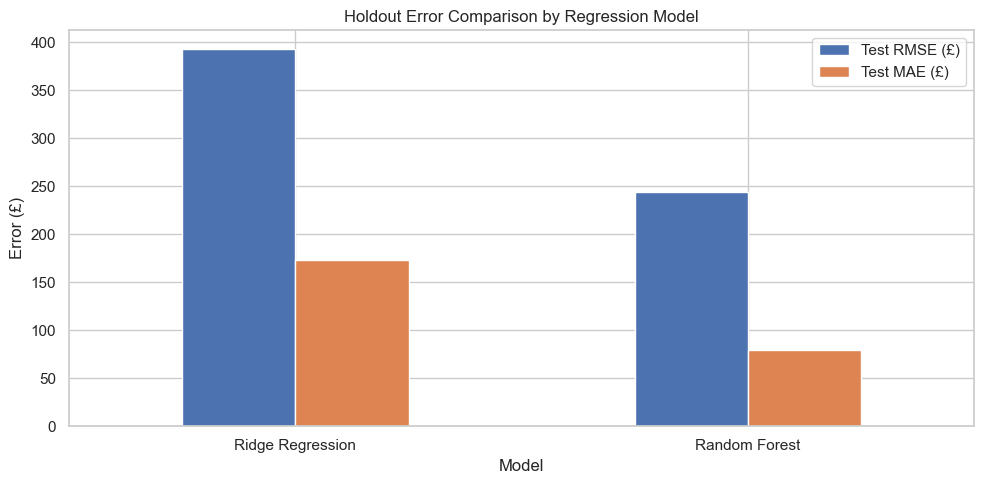

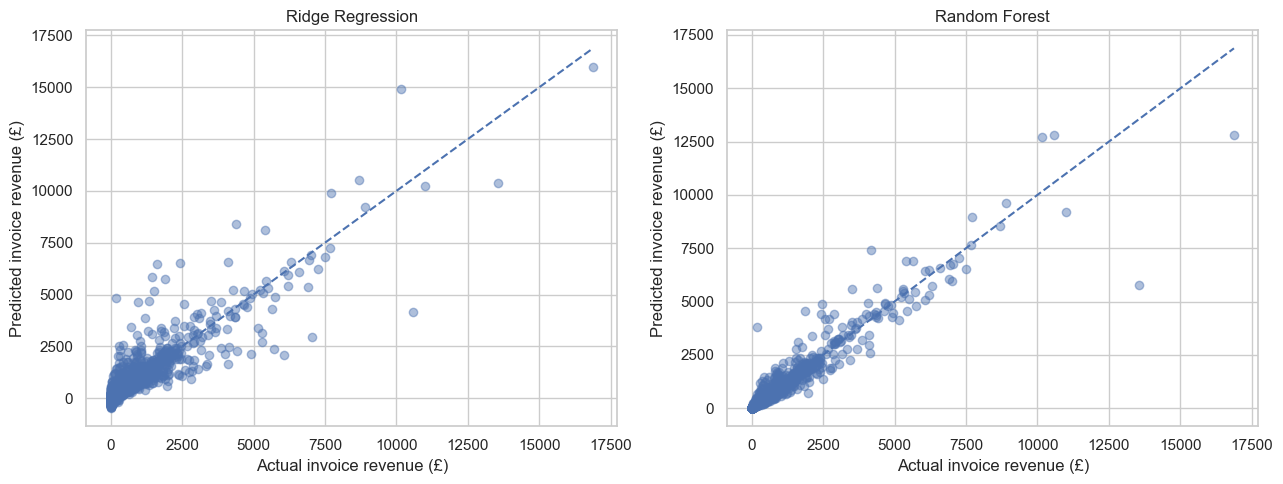

In [8]:
# Compare holdout RMSE and MAE.
metric_plot = results_df[["Test RMSE (£)", "Test MAE (£)"]]
ax = metric_plot.plot(kind="bar", figsize=(10, 5))
ax.set_title("Holdout Error Comparison by Regression Model")
ax.set_ylabel("Error (£)")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/model_error_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# Actual vs. predicted plots.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (model_name, predictions) in zip(axes, test_predictions.items()):
    ax.scatter(y_test, predictions, alpha=0.45)
    limit = max(float(y_test.max()), float(np.max(predictions)))
    ax.plot([0, limit], [0, limit], linestyle="--")
    ax.set_title(model_name)
    ax.set_xlabel("Actual invoice revenue (£)")
    ax.set_ylabel("Predicted invoice revenue (£)")
plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/actual_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()


## 8. Residual analysis and feature importance

Residuals are actual minus predicted revenue. A residual distribution centered around zero is desirable, although large invoices and skewed transaction values may produce wider errors. Random Forest feature importance is included as a descriptive model diagnostic; it does not establish causation.

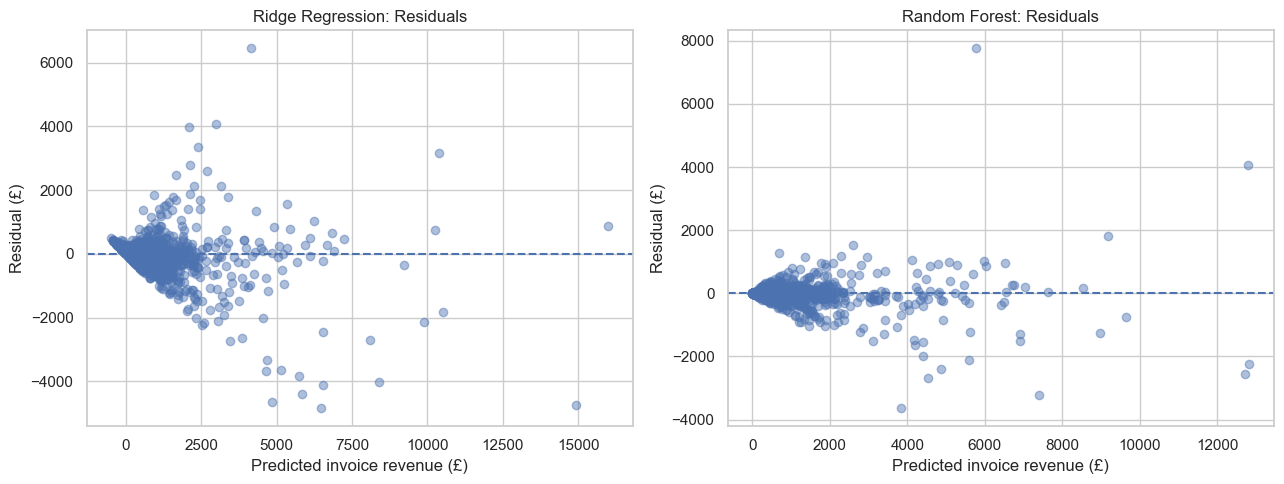

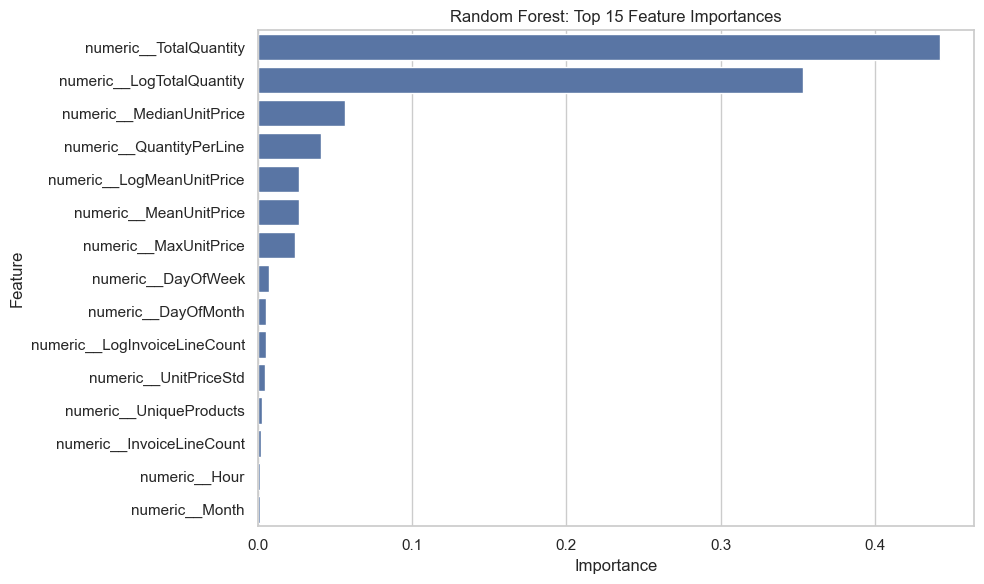

,Feature,Importance
2,numeric__TotalQuantity,0.442
15,numeric__LogTotalQuantity,0.353
4,numeric__MedianUnitPrice,0.056
12,numeric__QuantityPerLine,0.041
16,numeric__LogMeanUnitPrice,0.026
3,numeric__MeanUnitPrice,0.026
5,numeric__MaxUnitPrice,0.024
8,numeric__DayOfWeek,0.007
10,numeric__DayOfMonth,0.005
14,numeric__LogInvoiceLineCount,0.005


In [9]:
# Residual plot for each model.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (model_name, predictions) in zip(axes, test_predictions.items()):
    residuals = y_test.to_numpy() - predictions
    ax.scatter(predictions, residuals, alpha=0.45)
    ax.axhline(0, linestyle="--")
    ax.set_title(f"{model_name}: Residuals")
    ax.set_xlabel("Predicted invoice revenue (£)")
    ax.set_ylabel("Residual (£)")
plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/residual_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# Extract Random Forest feature importances after preprocessing.
rf_pipeline = fitted_models["Random Forest"]
encoded_names = rf_pipeline.named_steps["preprocess"].get_feature_names_out()
importances = rf_pipeline.named_steps["model"].feature_importances_

importance_df = (
    pd.DataFrame({"Feature": encoded_names, "Importance": importances})
    .sort_values("Importance", ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Random Forest: Top 15 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/random_forest_feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()
display(importance_df)


## 9. Interpretation, limitations, and conclusion

Use the metric table and plots generated above to support the conclusions in the README. Do not treat one metric as the only definition of model quality: RMSE penalizes large errors more heavily than MAE, and cross-validation results show how performance varies across training folds.

### Modeling limitations
1. The data cover one retailer from December 2010 to December 2011; results may not generalize to current retail settings.
2. Invoice revenue is strongly connected to quantities and prices in the basket. The model estimates invoice value from observed basket composition, not demand before a basket exists.
3. The distribution is right-skewed, with a small number of high-value invoices. These observations were not automatically deleted because they may represent legitimate wholesale orders.
4. Random train/test splitting evaluates performance on invoices drawn from the same historical period. A future-time holdout would be a useful extension for assessing temporal generalization.
5. Customer IDs and invoice numbers are excluded as identifiers. Country is retained as contextual information and one-hot encoded.

### Conclusion
The notebook creates invoice-level features, trains Ridge and Random Forest regressors, compares cross-validation and holdout metrics, and visualizes prediction errors. The final model choice should consider both cross-validation stability and held-out test performance, as well as the intended use of the estimate.


## References

Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

Chen, D., Sain, S. L., & Guo, K. (2012). Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining. *Journal of Database Marketing & Customer Strategy Management, 19*, 197–208. https://doi.org/10.1057/dbm.2012.17
